# 07_03 — BERTopic Complaint Clustering Evaluation

Evaluates the complaint topics from notebook 05 (BGE-M3 + BERTopic) using 3 metrics:

| # | Metric | What it answers |
|---|---|---|
| 1 | **Silhouette Score** | Are a product's topic assignments tight and well-separated in BGE-M3 space? |
| 2 | **Topic Coverage** | How much of each product's complaints do its top topics explain? |
| 3 | **Keyword Distinctiveness** | Do topics capture different complaint themes? |

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score
from tqdm.auto import tqdm
import itertools

from utils.embeddings import embed_texts

DATA_DIR = os.path.abspath('../data/processed/sentiment')
MIN_COMPLAINTS = 5
TOP_TOPICS     = 3

print('Libraries loaded.')

W1105 21:16:17.219000 22470 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Libraries loaded.


## 1. Load Data

In [2]:
# product-topic results and per-review assignments from notebook 05
cluster_df = pd.read_parquet(os.path.join(DATA_DIR, 'complaint_clusters.parquet'))
complaints = pd.read_parquet(os.path.join(DATA_DIR, 'complaint_topic_assignments.parquet')).reset_index(drop=True)
print(f'Products with topics     : {cluster_df["product_id"].nunique():,}')
print(f'Complaint reviews loaded : {len(complaints):,}')
print(f'Products                 : {complaints["product_id"].nunique():,}')

Products with topics     : 16
Complaint reviews loaded : 352
Products                 : 27


## 2. Re-encode Reviews with BGE-M3

In [3]:
all_texts = complaints['review'].tolist()
all_embeddings = embed_texts(all_texts, batch_size=64, show_progress_bar=True)
complaints['emb_idx'] = range(len(complaints))
print(f'Encoded {len(all_embeddings):,} reviews  |  embedding dim: {all_embeddings.shape[1]}')

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 46147.02it/s]

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

Batches:  17%|█▋        | 1/6 [00:12<01:01, 12.24s/it]

Batches:  33%|███▎      | 2/6 [00:23<00:45, 11.42s/it]

Batches:  50%|█████     | 3/6 [00:32<00:31, 10.41s/it]

Batches:  67%|██████▋   | 4/6 [00:37<00:16,  8.23s/it]

Batches:  83%|████████▎ | 5/6 [00:39<00:06,  6.27s/it]

Batches: 100%|██████████| 6/6 [00:40<00:00,  4.45s/it]

Batches: 100%|██████████| 6/6 [00:40<00:00,  6.82s/it]

Encoded 352 reviews  |  embedding dim: 1024


## 3. Silhouette Score

Measures how well each review fits its assigned topic vs the nearest other topic (cosine distance on BGE-M3 embeddings), per product.
Range **-1 to +1** — higher is better. Score > 0.2 is acceptable for text clustering.

Silhouette:   0%|          | 0/27 [00:00<?, ?it/s]

Silhouette: 100%|██████████| 27/27 [00:00<00:00, 280.69it/s]

Products evaluated : 12

Silhouette Score (higher = better separated topics):
  Mean   : 0.1340
  Median : 0.1195
  Min    : 0.0195
  Max    : 0.2823

Products with score > 0.2 : 2 / 12


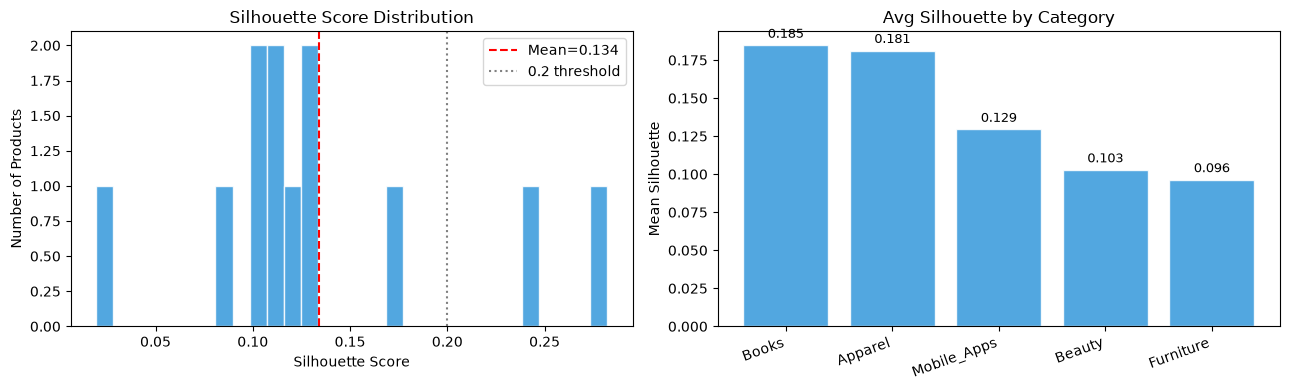

In [4]:
sil_rows = []

for product_id, grp in tqdm(complaints.groupby('product_id'), desc='Silhouette'):
    if len(grp) < MIN_COMPLAINTS:
        continue
    labels = grp['topic'].values
    n_topics = len(set(labels))
    if n_topics < 2 or n_topics >= len(grp):
        continue
    embeddings = all_embeddings[grp['emb_idx'].values]
    score = silhouette_score(embeddings, labels, metric='cosine')
    sil_rows.append({
        'product_id'      : product_id,
        'product_category': grp.iloc[0]['product_category'],
        'n_complaints'    : len(grp),
        'n_topics'        : n_topics,
        'silhouette_score': round(score, 4),
    })

sil_df = pd.DataFrame(sil_rows)
print(f'Products evaluated : {len(sil_df):,}')
print('\nSilhouette Score (higher = better separated topics):')
print(f'  Mean   : {sil_df["silhouette_score"].mean():.4f}')
print(f'  Median : {sil_df["silhouette_score"].median():.4f}')
print(f'  Min    : {sil_df["silhouette_score"].min():.4f}')
print(f'  Max    : {sil_df["silhouette_score"].max():.4f}')
print(f'\nProducts with score > 0.2 : {(sil_df["silhouette_score"] > 0.2).sum():,} / {len(sil_df):,}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(sil_df['silhouette_score'], bins=30, color='#3498db', edgecolor='white', alpha=0.85)
axes[0].axvline(sil_df['silhouette_score'].mean(), color='red', linestyle='--', label=f'Mean={sil_df["silhouette_score"].mean():.3f}')
axes[0].axvline(0.2, color='gray', linestyle=':', label='0.2 threshold')
axes[0].set_title('Silhouette Score Distribution', fontsize=12)
axes[0].set_xlabel('Silhouette Score')
axes[0].set_ylabel('Number of Products')
axes[0].legend()

cat_sil = sil_df.groupby('product_category')['silhouette_score'].mean().sort_values(ascending=False)
bars = axes[1].bar(cat_sil.index, cat_sil.values, color='#3498db', edgecolor='white', alpha=0.85)
for bar, val in zip(bars, cat_sil.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.003, f'{val:.3f}', ha='center', va='bottom', fontsize=9)
axes[1].set_title('Avg Silhouette by Category', fontsize=12)
axes[1].set_ylabel('Mean Silhouette')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

## 4. Topic Coverage

Share of each product's complaints explained by its top-`TOP_TOPICS` topics, plus the number of distinct topics per product.
BERTopic fixes the number of topics from the data (no K to tune), so this replaces the old elbow curve.

Global topics            : 15
Avg topics per product   : 2.00
Avg top-3 coverage     : 0.990


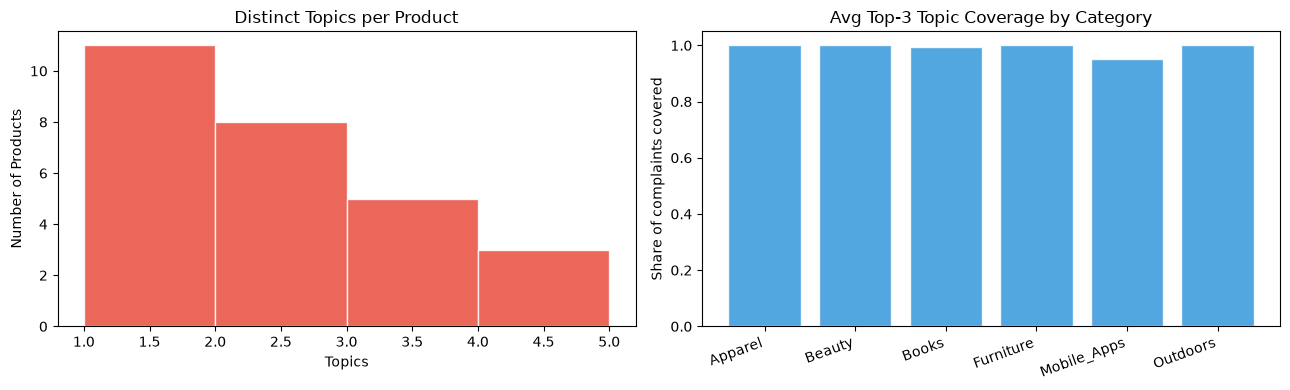

In [5]:
topics_per_product = complaints.groupby('product_id')['topic'].nunique()
total_per_product  = complaints.groupby('product_id').size()
top_per_product    = cluster_df.groupby('product_id')['complaint_count'].sum()
coverage = (top_per_product / total_per_product).dropna()
coverage_by_cat = (
    pd.DataFrame({'coverage': coverage})
    .join(complaints.drop_duplicates('product_id').set_index('product_id')['product_category'])
    .groupby('product_category')['coverage'].mean()
)

print(f'Global topics            : {complaints["topic"].nunique():,}')
print(f'Avg topics per product   : {topics_per_product.mean():.2f}')
print(f'Avg top-{TOP_TOPICS} coverage     : {coverage.mean():.3f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(topics_per_product, bins=range(1, int(topics_per_product.max()) + 2), color='#e74c3c', edgecolor='white', alpha=0.85)
axes[0].set_title('Distinct Topics per Product', fontsize=12)
axes[0].set_xlabel('Topics')
axes[0].set_ylabel('Number of Products')

axes[1].bar(coverage_by_cat.index, coverage_by_cat.values, color='#3498db', edgecolor='white', alpha=0.85)
axes[1].set_title(f'Avg Top-{TOP_TOPICS} Topic Coverage by Category', fontsize=12)
axes[1].set_ylabel('Share of complaints covered')
axes[1].set_ylim(0, 1.05)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

## 5. Keyword Distinctiveness

Measures how much c-TF-IDF keyword sets overlap between clusters for the same product.
**Low overlap = clusters capture different complaint themes (good).**
Computed as Jaccard similarity between keyword sets of each cluster pair.

Keyword Distinctiveness (1 - Jaccard overlap — higher = more distinct themes):
  Mean   : 0.9495
  Median : 1.0000

Products with full distinctiveness (0 keyword overlap): 7 / 12


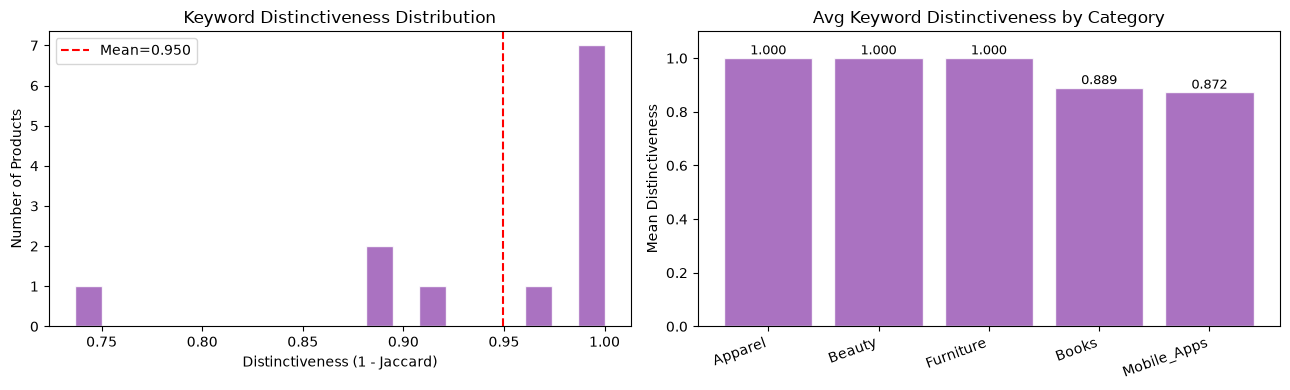

In [6]:
def jaccard(set_a, set_b):
    a, b = set(set_a), set(set_b)
    return len(a & b) / len(a | b) if (a | b) else 0.0

distinct_rows = []
for product_id, grp in cluster_df.groupby('product_id'):
    keywords_per_cluster = [
        set(row['theme_keywords'].split(', '))
        for _, row in grp.iterrows()
    ]
    pairs = list(itertools.combinations(range(len(keywords_per_cluster)), 2))
    if not pairs:
        continue
    avg_jaccard = np.mean([jaccard(keywords_per_cluster[i], keywords_per_cluster[j]) for i, j in pairs])
    distinct_rows.append({
        'product_id'         : product_id,
        'product_category'   : grp.iloc[0]['product_category'],
        'avg_jaccard'        : round(avg_jaccard, 4),
        'distinctiveness'    : round(1 - avg_jaccard, 4),
    })

distinct_df = pd.DataFrame(distinct_rows)
print('Keyword Distinctiveness (1 - Jaccard overlap — higher = more distinct themes):')
print(f'  Mean   : {distinct_df["distinctiveness"].mean():.4f}')
print(f'  Median : {distinct_df["distinctiveness"].median():.4f}')
print(f'\nProducts with full distinctiveness (0 keyword overlap): {(distinct_df["avg_jaccard"] == 0).sum():,} / {len(distinct_df):,}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(distinct_df['distinctiveness'], bins=20, color='#9b59b6', edgecolor='white', alpha=0.85)
axes[0].axvline(distinct_df['distinctiveness'].mean(), color='red', linestyle='--',
                label=f'Mean={distinct_df["distinctiveness"].mean():.3f}')
axes[0].set_title('Keyword Distinctiveness Distribution', fontsize=12)
axes[0].set_xlabel('Distinctiveness (1 - Jaccard)')
axes[0].set_ylabel('Number of Products')
axes[0].legend()

cat_dist = distinct_df.groupby('product_category')['distinctiveness'].mean().sort_values(ascending=False)
bars = axes[1].bar(cat_dist.index, cat_dist.values, color='#9b59b6', edgecolor='white', alpha=0.85)
for bar, val in zip(bars, cat_dist.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.003, f'{val:.3f}', ha='center', va='bottom', fontsize=9)
axes[1].set_title('Avg Keyword Distinctiveness by Category', fontsize=12)
axes[1].set_ylabel('Mean Distinctiveness')
axes[1].set_ylim(0, 1.1)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

## 6. Overall Summary

  Metric                            Score
  Avg Silhouette Score             0.1340
  Avg Topics per Product             2.00
  Avg Top-3 Topic Coverage         0.9898
  Avg Keyword Distinctiveness      0.9495

Per-category summary:
                  silhouette_score  distinctiveness
product_category                                   
Apparel                      0.181            1.000
Beauty                       0.103            1.000
Books                        0.185            0.889
Furniture                    0.096            1.000
Mobile_Apps                  0.129            0.872


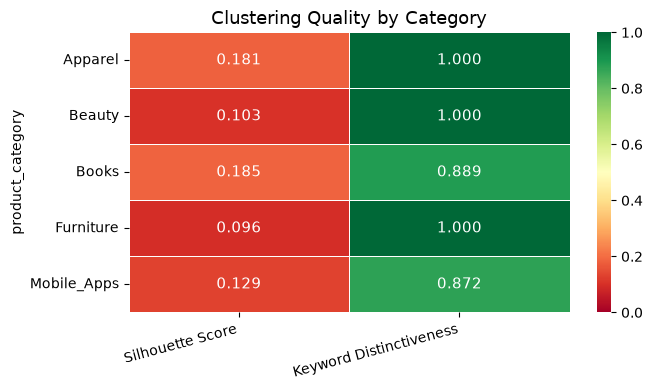

In [7]:
print('=' * 50)
print(f'  {"Metric":<30} {"Score":>8}')
print('=' * 50)
print(f'  {"Avg Silhouette Score":<30} {sil_df["silhouette_score"].mean():>8.4f}')
print(f'  {"Avg Topics per Product":<30} {topics_per_product.mean():>8.2f}')
print(f'  {"Avg Top-3 Topic Coverage":<30} {coverage.mean():>8.4f}')
print(f'  {"Avg Keyword Distinctiveness":<30} {distinct_df["distinctiveness"].mean():>8.4f}')
print('=' * 50)

# combined heatmap
combined = (
    sil_df.groupby('product_category')[['silhouette_score']].mean()
    .join(distinct_df.groupby('product_category')[['distinctiveness']].mean())
).round(3)
print('\nPer-category summary:')
print(combined.to_string())

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(combined, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0, vmax=1,
            linewidths=0.5, ax=ax, annot_kws={'size': 11})
ax.set_title('Clustering Quality by Category', fontsize=13)
ax.set_xticklabels(['Silhouette Score', 'Keyword Distinctiveness'], rotation=15, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

## 7. Save Results

In [8]:
eval_df = sil_df.merge(distinct_df[['product_id', 'avg_jaccard', 'distinctiveness']], on='product_id', how='left')
out_path = os.path.join(DATA_DIR, 'clustering_eval_scores.parquet')
eval_df.to_parquet(out_path, index=False)
print(f'Saved {len(eval_df):,} rows → {out_path}')
print(eval_df.describe().round(3).to_string())

Saved 12 rows → /Users/varsha/Documents/GitHub/product-review-intelligence-platform/data/processed/sentiment/clustering_eval_scores.parquet
       n_complaints  n_topics  silhouette_score  avg_jaccard  distinctiveness
count        12.000    12.000            12.000       12.000           12.000
mean         22.833     2.833             0.134        0.050            0.950
std          20.971     0.835             0.070        0.081            0.081
min           5.000     2.000             0.020        0.000            0.737
25%           9.500     2.000             0.102        0.000            0.910
50%          14.500     3.000             0.119        0.000            1.000
75%          30.750     3.250             0.142        0.090            1.000
max          70.000     4.000             0.282        0.263            1.000
